In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [2]:
df = pd.read_csv("titanic.csv")

In [3]:
X = df[["Pclass","Sex","Age","SibSp","Parch","Fare"]].copy()
y = df["Survived"]

X["Sex"] = X["Sex"].map({"male":0,"female":1})

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [5]:
median_age = X_train["Age"].median()
X_train = X_train.fillna({"Age":median_age})
X_test = X_test.fillna({"Age":median_age})



In [6]:
dt_model = DecisionTreeClassifier(random_state = 42)
dt_model.fit(X_train,y_train)
dt_pred = dt_model.predict(X_test)

In [7]:
rf_model = RandomForestClassifier(n_estimators=100,bootstrap=True,random_state=42)
rf_model.fit(X_train,y_train)
rf_pred = rf_model.predict(X_test)


In [8]:
results = pd.DataFrame([{"Model":name,
                         "Accuracy":accuracy_score(y_test,pred),
                        "Precision":precision_score(y_test,pred),
                        "Recall":recall_score(y_test,pred),
                        "F1-score":f1_score(y_test,pred)
                        }
                        for name, pred in [
                            ("Decision Tree",dt_pred),
                            ("Random Forest",rf_pred)
                        ]
                       ])

In [9]:
print(results.round(4).to_string(index=False))

        Model  Accuracy  Precision  Recall  F1-score
Decision Tree    0.8212     0.7937  0.7246    0.7576
Random Forest    0.8101     0.7778  0.7101    0.7424


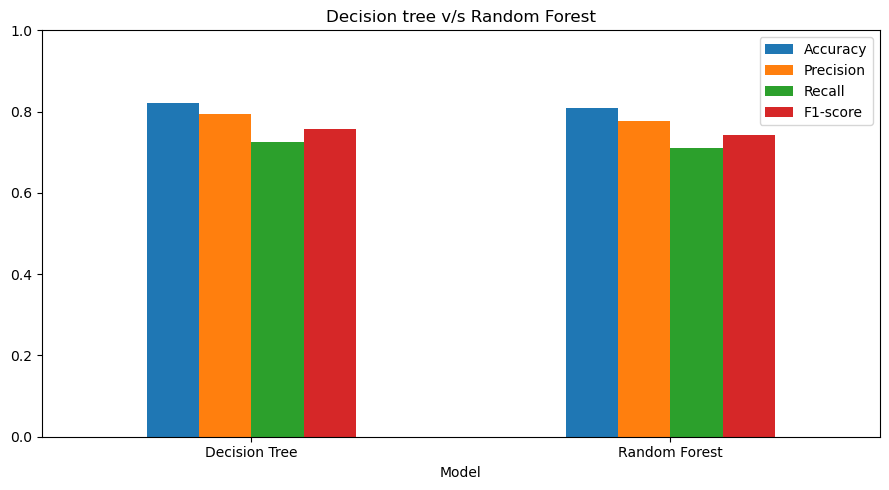

In [10]:
metric_cols = ["Accuracy","Precision","Recall","F1-score"]

ax = results.set_index("Model")[metric_cols].plot(kind="bar",figsize=(9,5),rot=0)
ax.set_title("Decision tree v/s Random Forest")
ax.set_ylim(0,1)
plt.tight_layout()
plt.show()

In [11]:
comparison = pd.DataFrame({"Actual Values":y_test.values,
                          "Decision Tree":dt_pred,
                          "Random Forest":rf_pred})

print(comparison.head(10).to_string(index=False))

 Actual Values  Decision Tree  Random Forest
             0              0              0
             0              0              0
             1              0              0
             0              0              0
             1              1              1
             1              0              0
             1              1              1
             0              1              1
             0              0              0
             0              0              0
